# 08 — Comparer les runs subset

Lit `checkpoints/<run>/history.json` (et `gold_sanity.json` s'il existe) pour
comparer des recettes entraînées sur **le même 25 % du train** (val pleine).

Les runs à comparer sont listés en dur dans `RUNS` (cellule suivante) :
commenter une ligne suffit pour retirer un checkpoint de l'analyse.

Le checkpoint se pilote sur la **val macro-AUC**. Le gold (58) et surtout
**Lateral OA / MCL** sont le signal attendu du T1 — un écart de macro-AUC
**&lt; 0,01** sur un subset de 924 études = bruit.

Tu peux relancer les cellules pendant qu'un run tourne encore : l'historique
s'écrit à chaque epoch.

In [37]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "checkpoints").exists() else Path.cwd().parent
CKPT = ROOT / "checkpoints"

# Checkpoints a comparer (noms de dossiers sous checkpoints/).
# Commenter une ligne pour l'exclure de l'analyse.
RUNS = [
    "subset_v8_frac025",
    "subset_v8_crop130_frac025",
    "subset_v9_t1_frac025",
    "subset_v9_t1_gate_frac025",
    "subset_v9_t1_gate2_frac025",
    "subset_v9_t1_gate3_frac025",
    "subset_v9_t1_gate4_frac025",
]
REF = "subset_v8_frac025"  # baseline pour les deltas

FOCUS = ["Lateral OA", "MCL", "ACL", "Medial Meniscus"]
TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA",
    "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's",
    "Contusion", "Fracture",
]

print("ROOT", ROOT)
print("checkpoints", CKPT.exists())

ROOT c:\Users\sulta\Documents\RSNA-comp
checkpoints True


In [38]:
def load_run(name: str) -> dict | None:
    d = CKPT / name
    hist_p = d / "history.json"
    if not hist_p.exists():
        print(f"  skip {name} : pas de history.json (pas encore d'epoch finie)")
        return None
    hist = pd.DataFrame(json.loads(hist_p.read_text(encoding="utf-8")))
    if hist.empty:
        print(f"  skip {name} : history.json vide")
        return None
    gold = None
    gp = d / "gold_sanity.json"
    if gp.exists():
        gold = json.loads(gp.read_text(encoding="utf-8"))
    cfg = {}
    last_p, best_p = d / "last.pt", d / "best.pt"
    # config : copie YAML sauvee a cote si presente, sinon on lit le ckpt plus tard
    uids = []
    up = d / "train_uids.txt"
    if up.exists():
        uids = [ln.strip() for ln in up.read_text(encoding="utf-8").splitlines() if ln.strip()]
    best_idx = hist["val_macro_auc"].idxmax()
    best_row = hist.loc[best_idx]
    return {
        "name": name,
        "dir": d,
        "hist": hist,
        "gold": gold,
        "uids": uids,
        "done": gp.exists(),
        "best_epoch": int(best_row["epoch"]),
        "best_val": float(best_row["val_macro_auc"]),
        "best_gold": float(best_row["gold_macro_auc"]) if "gold_macro_auc" in hist.columns and pd.notna(best_row.get("gold_macro_auc")) else None,
        "last_epoch": int(hist["epoch"].max()),
    }


wanted = list(RUNS)
runs = []
print("runs demandes :", wanted)
for name in wanted:
    rec = load_run(name)
    if rec is None:
        continue
    runs.append(rec)
    gold_txt = f"gold {rec['best_gold']:.3f}" if rec["best_gold"] is not None else "gold n/a"
    etat = "termine" if rec["done"] else f"en cours (epoch {rec['last_epoch']})"
    print(f"  {name}: {etat} | best val {rec['best_val']:.4f} @ ep {rec['best_epoch']} | {gold_txt} | n_train {len(rec['uids']) or '?'}")

if not runs:
    raise SystemExit("aucun history.json — lance d'abord un train subset")

runs demandes : ['subset_v8_frac025', 'subset_v9_t1_frac025', 'subset_v9_t1_gate2_frac025', 'subset_v9_t1_gate3_frac025', 'subset_v9_t1_gate4_frac025', 'subset_v9_t1_gate_frac025']
  subset_v8_frac025: termine | best val 0.6896 @ ep 10 | gold 0.698 | n_train 924
  subset_v9_t1_frac025: termine | best val 0.6416 @ ep 10 | gold 0.629 | n_train 924
  subset_v9_t1_gate2_frac025: en cours (epoch 3) | best val 0.5277 @ ep 1 | gold 0.535 | n_train 924
  subset_v9_t1_gate3_frac025: en cours (epoch 3) | best val 0.5563 @ ep 2 | gold 0.593 | n_train 924
  subset_v9_t1_gate4_frac025: termine | best val 0.5435 @ ep 7 | gold 0.558 | n_train 924
  subset_v9_t1_gate_frac025: termine | best val 0.5708 @ ep 1 | gold 0.574 | n_train 924


## Tableau résumé

Meilleure epoch = argmax de la val macro-AUC (comme le `best.pt`).

In [39]:
rows = []
for r in runs:
    last = r["hist"].iloc[-1]
    rows.append({
        "run": r["name"],
        "etat": "termine" if r["done"] else f"epoch {r['last_epoch']}",
        "n_train": len(r["uids"]) or None,
        "best_epoch": r["best_epoch"],
        "best_val_auc": r["best_val"],
        "best_gold_auc": r["best_gold"],
        "last_train_loss": float(last["loss"]),
        "last_val_loss": float(last["val_loss"]) if "val_loss" in last else None,
        "last_val_auc": float(last["val_macro_auc"]),
    })
summary = pd.DataFrame(rows).set_index("run")
display(summary.round(4))

if REF in summary.index and len(summary) > 1:
    print("\ndelta vs", REF, "(best val AUC)")
    ref_val = summary.loc[REF, "best_val_auc"]
    for name, row in summary.iterrows():
        if name == REF:
            continue
        d = row["best_val_auc"] - ref_val
        print(f"  {name}: {d:+.4f}  {'(bruit, <0.01)' if abs(d) < 0.01 else ''}")

,etat,n_train,best_epoch,best_val_auc,best_gold_auc,last_train_loss,last_val_loss,last_val_auc
run,,,,,,,,
subset_v8_frac025,termine,924,10,0.6896,0.6976,0.4712,0.4729,0.6896
subset_v9_t1_frac025,termine,924,10,0.6416,0.6287,0.4984,0.4937,0.6416
subset_v9_t1_gate2_frac025,epoch 3,924,1,0.5277,0.5349,0.5621,0.5735,0.4938
subset_v9_t1_gate3_frac025,epoch 3,924,2,0.5563,0.5928,0.5798,0.5734,0.4813
subset_v9_t1_gate4_frac025,termine,924,7,0.5435,0.5584,0.5256,0.5186,0.5354
subset_v9_t1_gate_frac025,termine,924,1,0.5708,0.5739,0.5803,0.5773,0.5379



delta vs subset_v8_frac025 (best val AUC)
  subset_v9_t1_frac025: -0.0480  
  subset_v9_t1_gate2_frac025: -0.1619  
  subset_v9_t1_gate3_frac025: -0.1332  
  subset_v9_t1_gate4_frac025: -0.1461  
  subset_v9_t1_gate_frac025: -0.1188  


## Courbes (tous les runs superposés)

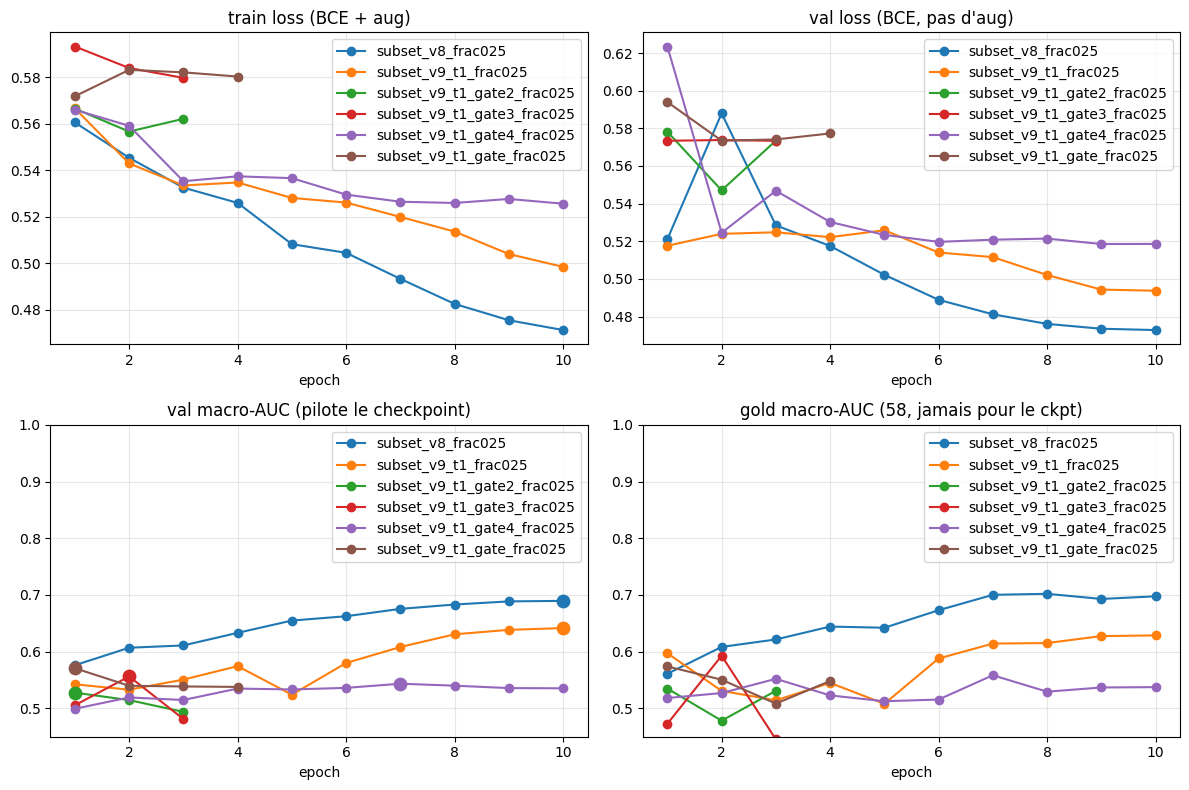

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for r in runs:
    h = r["hist"]
    axes[0, 0].plot(h.epoch, h.loss, marker="o", label=r["name"])
    if "val_loss" in h.columns:
        axes[0, 1].plot(h.epoch, h.val_loss, marker="o", label=r["name"])
    axes[1, 0].plot(h.epoch, h.val_macro_auc, marker="o", label=r["name"])
    if "gold_macro_auc" in h.columns:
        axes[1, 1].plot(h.epoch, h.gold_macro_auc, marker="o", label=r["name"])
    axes[1, 0].scatter([r["best_epoch"]], [r["best_val"]], s=80, zorder=5)

axes[0, 0].set_title("train loss (BCE + aug)")
axes[0, 1].set_title("val loss (BCE, pas d'aug)")
axes[1, 0].set_title("val macro-AUC (pilote le checkpoint)")
axes[1, 1].set_title("gold macro-AUC (58, jamais pour le ckpt)")
for ax in axes.ravel():
    ax.set_xlabel("epoch")
    ax.grid(True, alpha=0.3)
    ax.legend()
axes[1, 0].set_ylim(0.45, 1.0)
axes[1, 1].set_ylim(0.45, 1.0)
plt.tight_layout()
plt.show()

## AUC par cible à la meilleure epoch

Barres groupées = comparaison directe. Les cibles **FOCUS** (T1 : anatomie) sont en gras dans le tableau.

,subset_v8_frac025,subset_v9_t1_frac025,subset_v9_t1_gate2_frac025,subset_v9_t1_gate3_frac025,subset_v9_t1_gate4_frac025,subset_v9_t1_gate_frac025,d_subset_v9_t1_frac025,d_subset_v9_t1_gate2_frac025,d_subset_v9_t1_gate3_frac025,d_subset_v9_t1_gate4_frac025,d_subset_v9_t1_gate_frac025
ACL,0.651000,0.599000,0.505000,0.449000,0.545000,0.557000,-0.052000,-0.146000,-0.202000,-0.106000,-0.094000
MCL,0.636000,0.618000,0.420000,0.545000,0.504000,0.527000,-0.018000,-0.216000,-0.091000,-0.132000,-0.109000
Medial Meniscus,0.687000,0.643000,0.578000,0.563000,0.505000,0.585000,-0.044000,-0.110000,-0.124000,-0.182000,-0.103000
Lateral Meniscus,0.672000,0.613000,0.479000,0.539000,0.528000,0.536000,-0.058000,-0.193000,-0.132000,-0.143000,-0.136000
Medial OA,0.744000,0.714000,0.628000,0.574000,0.564000,0.629000,-0.030000,-0.116000,-0.170000,-0.180000,-0.115000
Lateral OA,0.679000,0.669000,0.568000,0.554000,0.517000,0.558000,-0.010000,-0.111000,-0.124000,-0.162000,-0.121000
PF OA,0.665000,0.649000,0.591000,0.570000,0.581000,0.596000,-0.016000,-0.074000,-0.094000,-0.084000,-0.069000
Effusion,0.818000,0.657000,0.583000,0.577000,0.509000,0.577000,-0.162000,-0.235000,-0.242000,-0.310000,-0.241000
Synovitis,0.706000,0.685000,0.523000,0.497000,0.574000,0.588000,-0.021000,-0.183000,-0.209000,-0.132000,-0.118000
Baker's,0.779000,0.674000,0.561000,0.542000,0.565000,0.587000,-0.105000,-0.217000,-0.237000,-0.213000,-0.192000


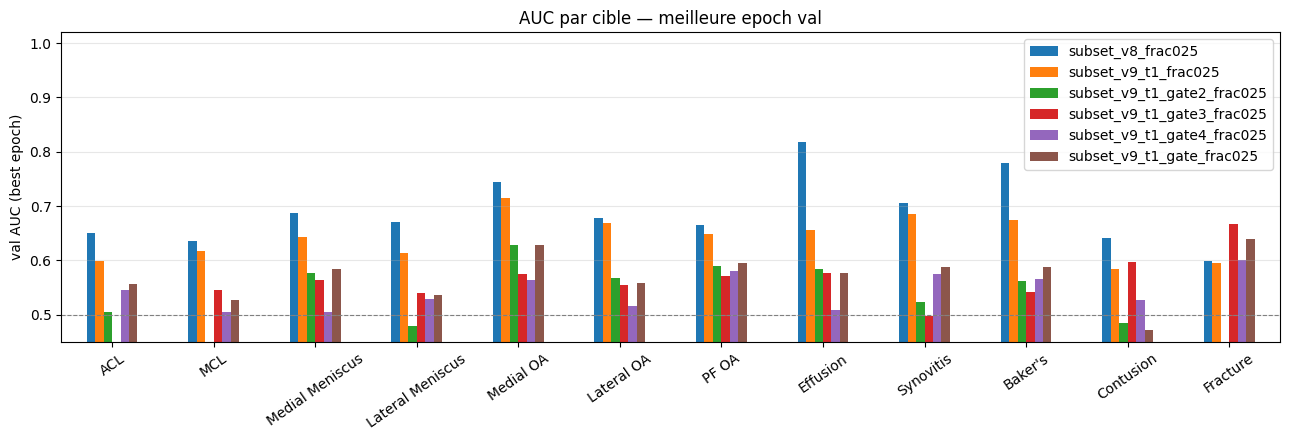

In [41]:
per = {}
for r in runs:
    row = r["hist"].loc[r["hist"]["val_macro_auc"].idxmax()]
    per[r["name"]] = {t: float(row[f"auc_{t}"]) for t in TARGETS if f"auc_{t}" in row.index}
per_df = pd.DataFrame(per).reindex(TARGETS)

if REF in per_df.columns:
    others = [c for c in per_df.columns if c != REF]
    for c in others:
        per_df[f"d_{c}"] = per_df[c] - per_df[REF]

display(per_df.round(3).style.apply(
    lambda s: ["font-weight: bold" if s.name in FOCUS else "" for _ in s],
    axis=1,
))

ax = per_df[[r["name"] for r in runs]].plot(
    kind="bar", figsize=(13, 4.5), rot=35,
)
ax.set_ylabel("val AUC (best epoch)")
ax.set_ylim(0.45, 1.02)
ax.set_title("AUC par cible — meilleure epoch val")
ax.axhline(0.5, color="gray", lw=0.8, ls="--")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Delta par cible vs v8

Positif = le run bat la référence sur cette cible. Le T1 devrait surtout
bouger Lateral OA / MCL / ménisques, pas Baker / Effusion (déjà portés par le fluide).

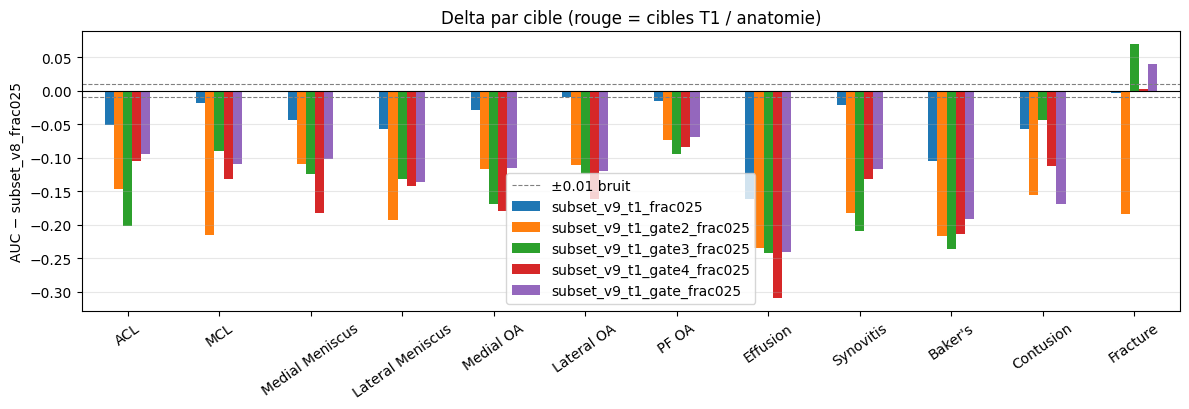

FOCUS (T1 attendu) :


,subset_v8_frac025,subset_v9_t1_frac025,subset_v9_t1_gate2_frac025,subset_v9_t1_gate3_frac025,subset_v9_t1_gate4_frac025,subset_v9_t1_gate_frac025,d_subset_v9_t1_frac025,d_subset_v9_t1_gate2_frac025,d_subset_v9_t1_gate3_frac025,d_subset_v9_t1_gate4_frac025,d_subset_v9_t1_gate_frac025
Lateral OA,0.679,0.669,0.568,0.554,0.517,0.558,-0.010,-0.111,-0.124,-0.162,-0.121
MCL,0.636,0.618,0.420,0.545,0.504,0.527,-0.018,-0.216,-0.091,-0.132,-0.109
ACL,0.651,0.599,0.505,0.449,0.545,0.557,-0.052,-0.146,-0.202,-0.106,-0.094
Medial Meniscus,0.687,0.643,0.578,0.563,0.505,0.585,-0.044,-0.110,-0.124,-0.182,-0.103


In [42]:
delta_cols = [c for c in per_df.columns if c.startswith("d_")]
if not delta_cols:
    print(f"pas de delta : il faut au moins 2 runs, dont REF={REF!r} charge.")
else:
    fig, ax = plt.subplots(figsize=(12, 4.2))
    d = per_df[delta_cols].copy()
    d.columns = [c[2:] for c in d.columns]
    colors_focus = ["#c44e52" if t in FOCUS else "#4c72b0" for t in d.index]
    # un seul comparateur : barres simples ; plusieurs : grouped
    if d.shape[1] == 1:
        ax.bar(range(len(d)), d.iloc[:, 0], color=colors_focus, edgecolor="black", lw=0.3)
        ax.set_xticks(range(len(d)))
        ax.set_xticklabels(d.index, rotation=35, ha="right")
        ax.set_ylabel(f"AUC {d.columns[0]} − {REF}")
    else:
        d.plot(kind="bar", ax=ax, rot=35)
        ax.set_ylabel(f"AUC − {REF}")
    ax.axhline(0.0, color="black", lw=0.8)
    ax.axhline(0.01, color="gray", ls="--", lw=0.8, label="±0.01 bruit")
    ax.axhline(-0.01, color="gray", ls="--", lw=0.8)
    ax.set_title("Delta par cible (rouge = cibles T1 / anatomie)")
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    print("FOCUS (T1 attendu) :")
    display(per_df.loc[FOCUS].round(3))

## Courbes des cibles FOCUS (toutes les epochs)

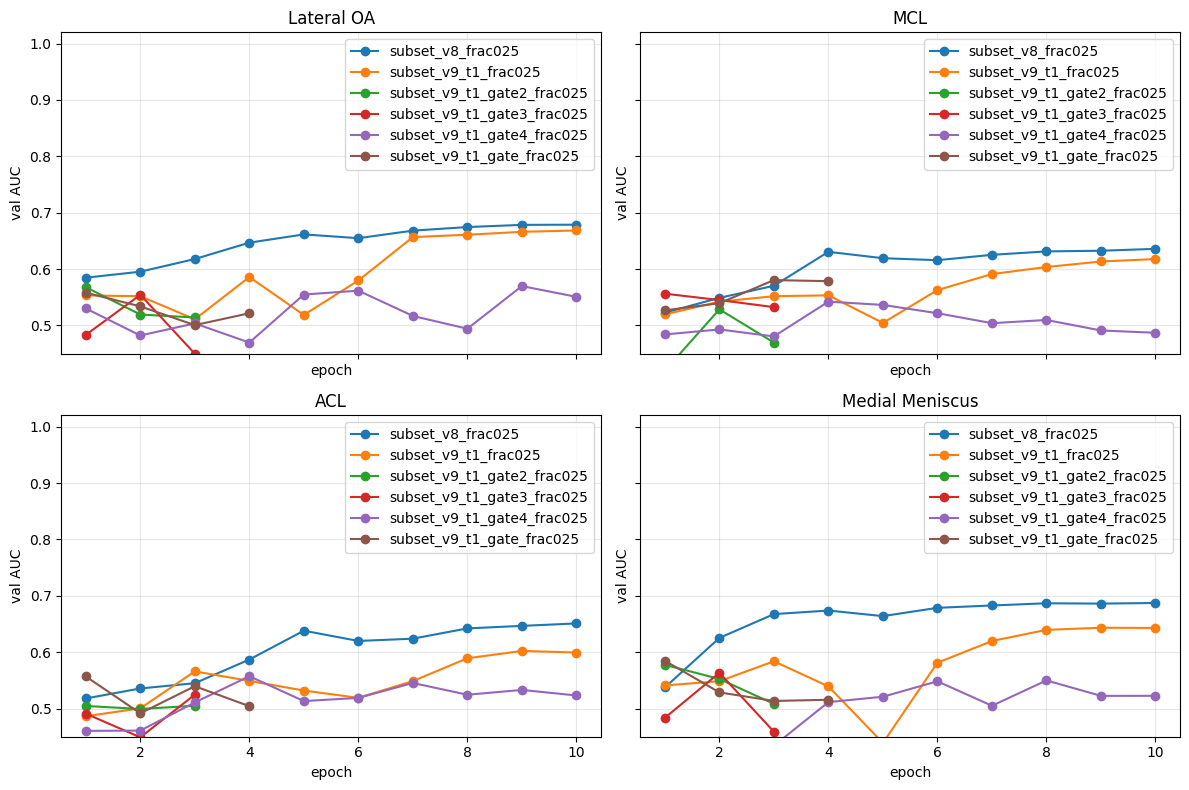

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, tgt in zip(axes.ravel(), FOCUS):
    col = f"auc_{tgt}"
    for r in runs:
        h = r["hist"]
        if col not in h.columns:
            continue
        ax.plot(h.epoch, h[col], marker="o", label=r["name"])
    ax.set_title(tgt)
    ax.set_ylim(0.45, 1.02)
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_xlabel("epoch")
    ax.set_ylabel("val AUC")
plt.tight_layout()
plt.show()

## Même subset ? (train_uids)

Les YAML subset partagent `train_frac_seed: 42`. L'overlap doit être 100 %.

In [44]:
uid_sets = {r["name"]: set(r["uids"]) for r in runs if r["uids"]}
if len(uid_sets) < 2:
    print("pas assez de train_uids.txt pour comparer (normal si un run n'a pas demarre)")
else:
    names = list(uid_sets)
    a, b = names[0], names[1]
    sa, sb = uid_sets[a], uid_sets[b]
    print(f"{a}: {len(sa)}  |  {b}: {len(sb)}")
    print(f"intersection {len(sa & sb)}  |  seulement {a} {len(sa - sb)}  |  seulement {b} {len(sb - sa)}")
    if sa == sb:
        print("OK : exactement les memes etudes train")
    else:
        print("ATTENTION : subsets differents, la comparaison d'archi n'est plus propre")

subset_v8_frac025: 924  |  subset_v9_t1_frac025: 924
intersection 924  |  seulement subset_v8_frac025 0  |  seulement subset_v9_t1_frac025 0
OK : exactement les memes etudes train


## Sanity gold du `best.pt` (si le run est fini)

`gold_sanity.json` n'est écrit qu'à la **fin** du script. Pendant l'entraînement,
utilise la courbe `gold_macro_auc` ci-dessus (loggée chaque epoch).

subset_v8_frac025: macro-AUC gold 0.6976  (best epoch 10)
subset_v9_t1_frac025: macro-AUC gold 0.6287  (best epoch 10)
subset_v9_t1_gate2_frac025: pas encore de gold_sanity.json
subset_v9_t1_gate3_frac025: pas encore de gold_sanity.json
subset_v9_t1_gate4_frac025: macro-AUC gold 0.5584  (best epoch 7)
subset_v9_t1_gate_frac025: macro-AUC gold 0.5739  (best epoch 1)


,subset_v8_frac025,subset_v9_t1_frac025,subset_v9_t1_gate4_frac025,subset_v9_t1_gate_frac025,d_subset_v9_t1_frac025,d_subset_v9_t1_gate4_frac025,d_subset_v9_t1_gate_frac025
ACL,0.555,0.430,0.464,0.407,-0.124,-0.090,-0.148
MCL,0.552,0.583,0.578,0.641,0.031,0.026,0.088
Medial Meniscus,0.680,0.614,0.525,0.476,-0.066,-0.154,-0.204
Lateral Meniscus,0.727,0.699,0.658,0.667,-0.028,-0.069,-0.060
Medial OA,0.750,0.732,0.612,0.678,-0.018,-0.137,-0.071
Lateral OA,0.768,0.631,0.453,0.716,-0.137,-0.315,-0.052
PF OA,0.630,0.681,0.528,0.654,0.051,-0.102,0.024
Effusion,0.930,0.675,0.542,0.558,-0.256,-0.389,-0.372
Synovitis,0.719,0.643,0.665,0.591,-0.076,-0.053,-0.127
Baker's,0.799,0.681,0.621,0.582,-0.118,-0.178,-0.216


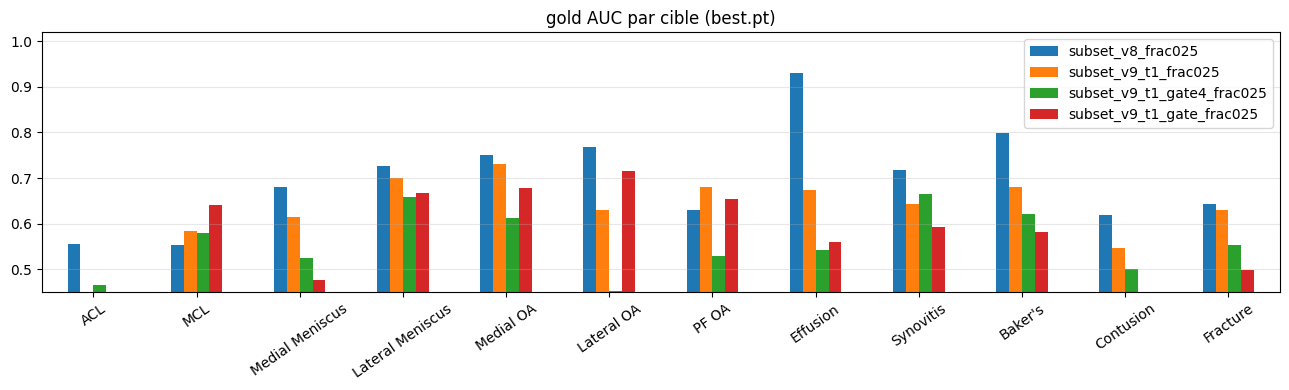

In [45]:
gcols = {}
for r in runs:
    if not r["gold"]:
        print(f"{r['name']}: pas encore de gold_sanity.json")
        continue
    g = r["gold"]
    print(f"{r['name']}: macro-AUC gold {g['macro_auc']:.4f}  (best epoch {g.get('epoch', '?')})")
    gcols[r["name"]] = pd.Series(g["per_target"])
if gcols:
    gdf = pd.DataFrame(gcols).reindex(TARGETS)
    if REF in gdf.columns:
        for c in gdf.columns:
            if c != REF:
                gdf[f"d_{c}"] = gdf[c] - gdf[REF]
    display(gdf.round(3))
    gdf[[r["name"] for r in runs if r["name"] in gdf.columns]].plot(
        kind="bar", figsize=(13, 4), rot=35, title="gold AUC par cible (best.pt)",
    )
    plt.ylim(0.45, 1.02)
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

## Comment lire

1. **Val macro-AUC** : critère principal. Δ &lt; 0,01 → on ne déclare pas de gagnant.
2. **Lateral OA / MCL** : si v9 gagne surtout là, le T1 sert. Si Baker/Effusion
   bougent et pas l'anatomie, ce n'est pas le levier T1.
3. **Gold** : n=58, très bruité. Un écart gold sans écart val n'est pas une preuve.
4. Si v9 gagne clairement : relancer `configs/kneenet_v9.yaml` sur **tout** le train.
   Sinon garder v8 (`configs/kneenet_v8.yaml`) pour la soumission.

Pour rafraîchir pendant que v9 tourne : **re-exécuter à partir de la cellule Load**.